In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import leidenalg
import umap

In [ ]:
script_loc = Path('clustering.ipynb').parent.resolve()
data_loc = script_loc.parent / "data/intermediate"
resources_loc = script_loc.parent / 'resources'

hmdata = sc.read_h5ad(data_loc/ 'hm_adjust.h5ad')
smdata = sc.read_h5ad(data_loc/ 'sr_adjust.h5ad')
sc.settings.figdir = script_loc.parent / 'outputs/clustering_figures'

In [3]:
hmdata

AnnData object with n_obs × n_vars = 6450 × 24087
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 

In [4]:
smdata

AnnData object with n_obs × n_vars = 6450 × 24087
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 

In [5]:
#Perform leiden clustering at 2 different resolutions, saving values in seperate columns
sc.tl.leiden(hmdata, resolution=0.3)
hmdata.obs['leiden0.3'] = hmdata.obs['leiden'].copy()
sc.tl.leiden(hmdata, resolution=0.5)
hmdata.obs['leiden0.5'] = hmdata.obs['leiden'].copy()
hmdata.obs = hmdata.obs.drop(columns=['leiden'])

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\3233231155.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(hmdata, resolution=0.3)
C:\Users\chris\AppData\Local\Temp\ipykernel_4368\3233231155.py:4: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(hmda

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\3259847128.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(hmdata,


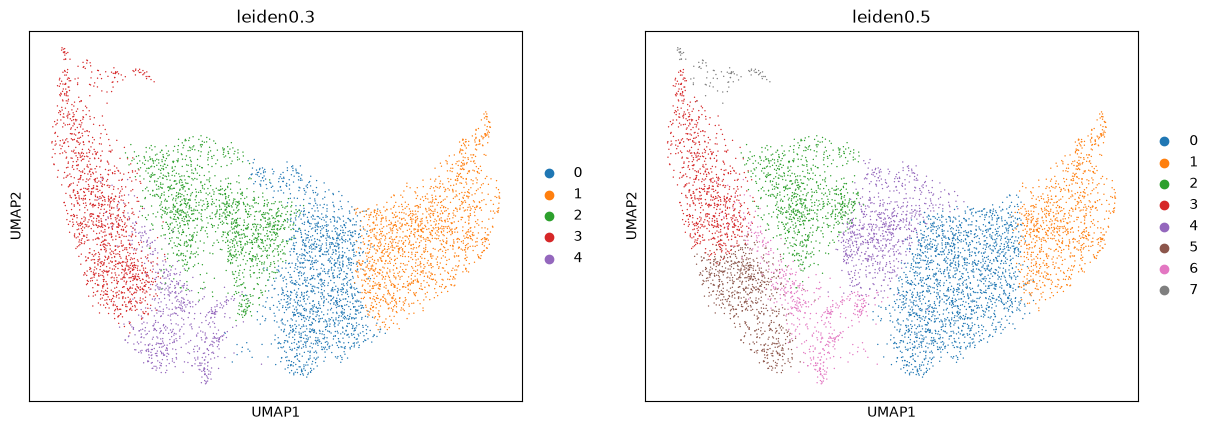

In [6]:
#Plot and save clusters
sc.pl.umap(hmdata, 
           color=['leiden0.3', 'leiden0.5'],
           size=4,
           save='_hm_clusters_unlabeled.png')

In [7]:
hmdata

AnnData object with n_obs × n_vars = 6450 × 24087
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden0.3', 'leiden0.5'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_inte

In [8]:
#Perform leiden clustering at 2 different resolutions, saving values in seperate columns
sc.tl.leiden(smdata, resolution=0.3)
smdata.obs['leiden0.3'] = smdata.obs['leiden'].copy()
sc.tl.leiden(smdata, resolution=0.9)
smdata.obs['leiden0.9'] = smdata.obs['leiden'].copy()
smdata.obs = smdata.obs.drop(columns=['leiden'])

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\329998747.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(smdata, resolution=0.3)
C:\Users\chris\AppData\Local\Temp\ipykernel_4368\329998747.py:4: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(smdata

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\3776863646.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(smdata,


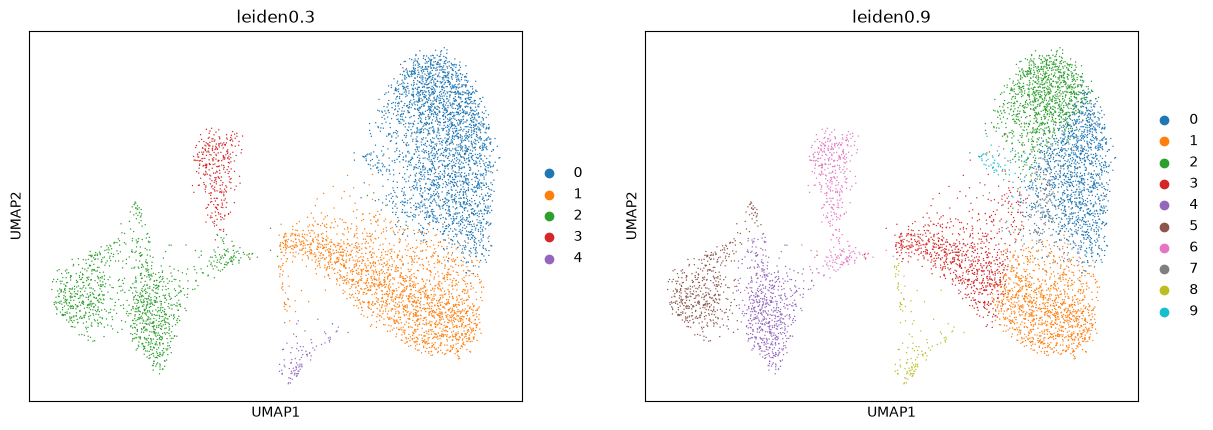

In [9]:
#Plot and save clusters
sc.pl.umap(smdata, 
           color=['leiden0.3', 'leiden0.9'],
           size=4,
           save='_sr_clusters_unlabeled.png')

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\890565243.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(smdata,


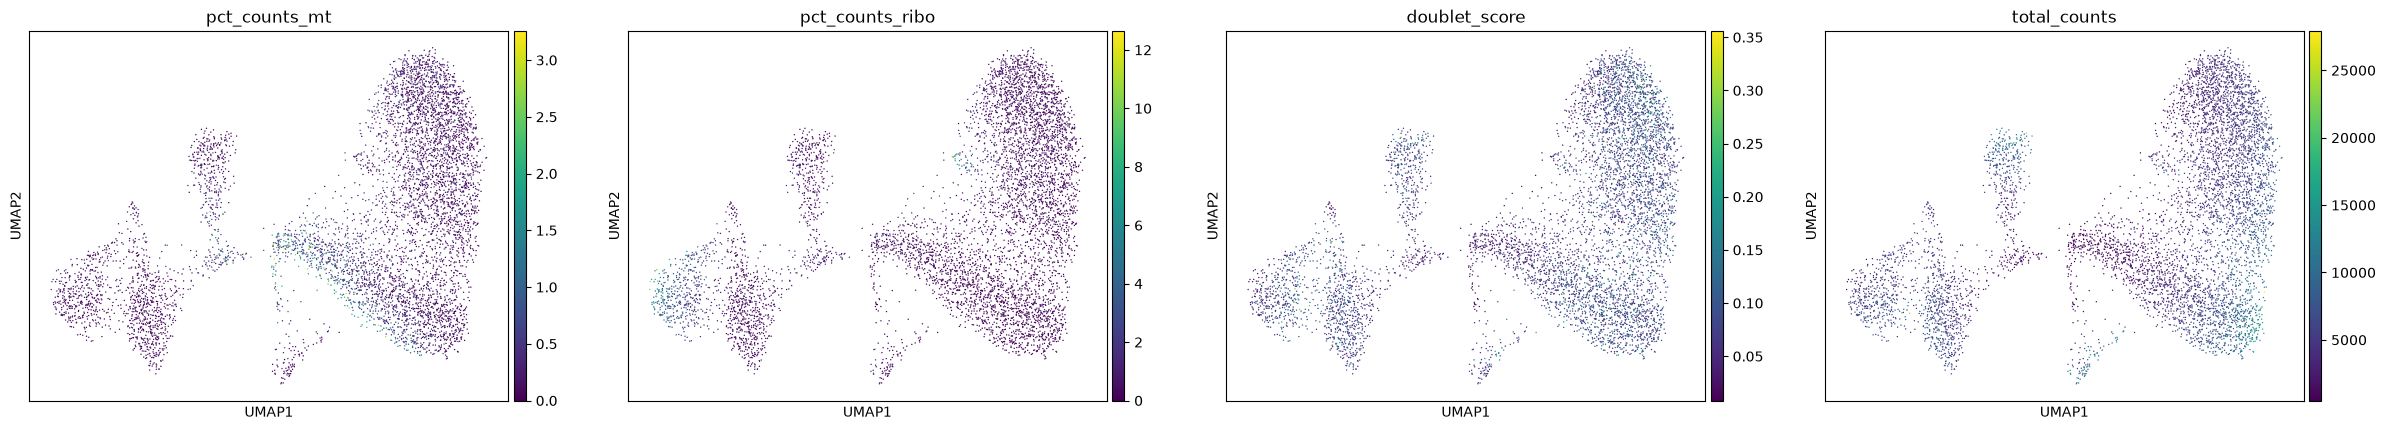

In [10]:
#Plot umap colored by qc metrics
sc.pl.umap(smdata, 
           color=['pct_counts_mt', 'pct_counts_ribo', 'doublet_score', 'total_counts'],
           size=4,
           save='_sr_qc.png'
           )

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\3014259691.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(hmdata,


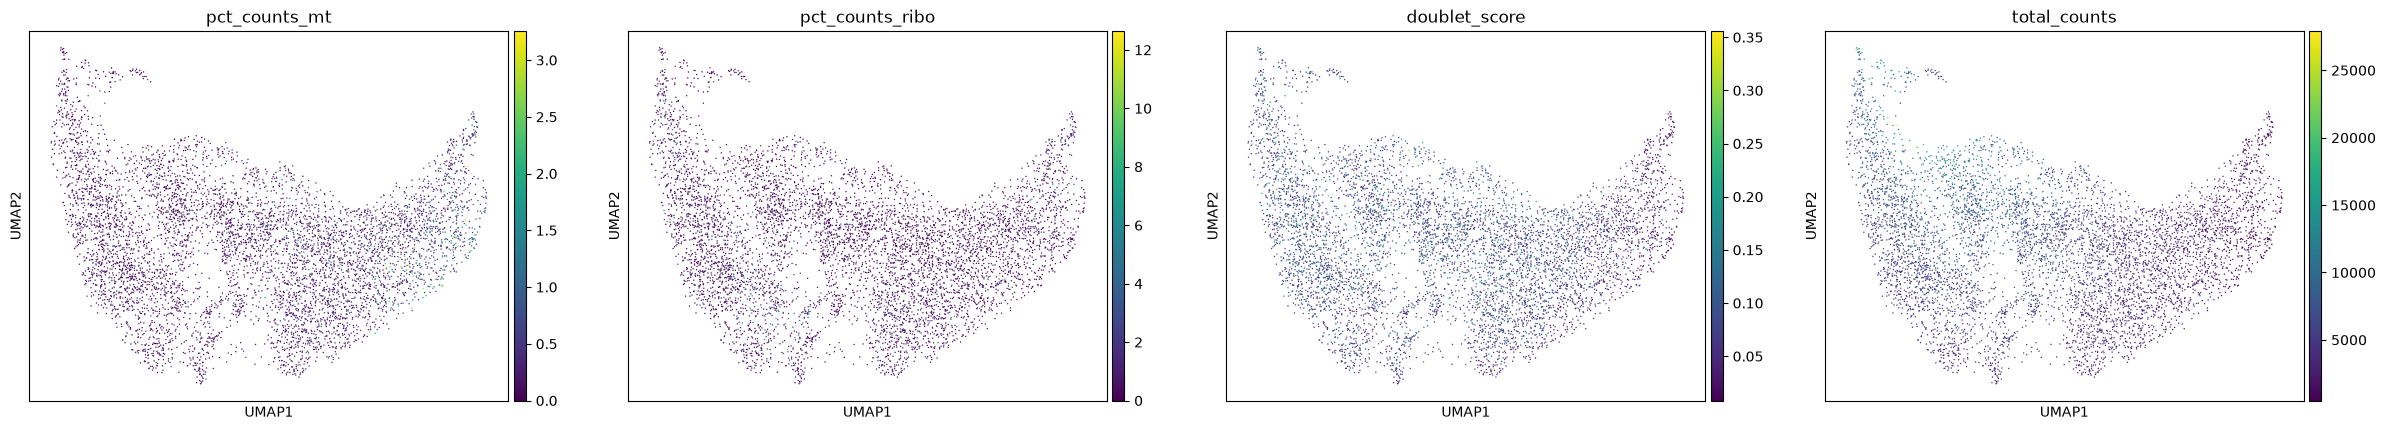

In [11]:
#Plot umap colored by qc metrics
sc.pl.umap(hmdata, 
           color=['pct_counts_mt', 'pct_counts_ribo', 'doublet_score', 'total_counts'],
           size=4,
           save='_hm_qc.png'
           )

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\3214073336.py:8: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.rank_genes_groups_dotplot(smdata,


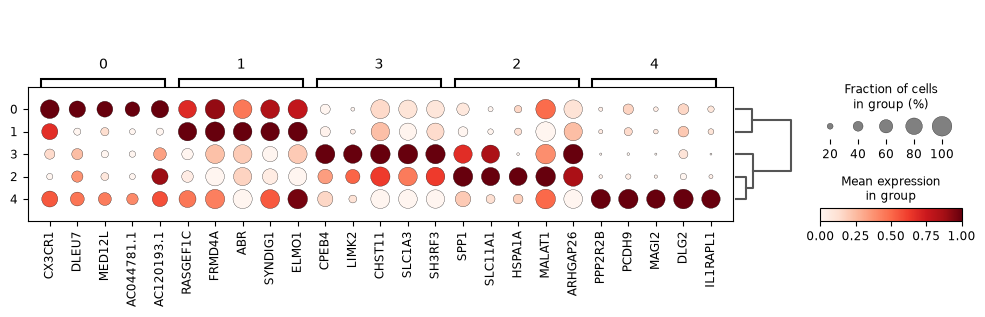

In [12]:
#Find cluster-specific differentially expressed genes and plot for leiden 0.3 and then 0.9
sc.tl.rank_genes_groups(smdata, 
                        use_raw=False, 
                        layer='CP10k_counts', 
                        groupby="leiden0.3", 
                        method="wilcoxon",
                        key_added='markers_0.3')
sc.pl.rank_genes_groups_dotplot(smdata, 
                                use_raw=False, 
                                layer='CP10k_counts', 
                                groupby="leiden0.3", 
                                standard_scale="var", 
                                n_genes=5,
                                key='markers_0.3',
                                save='_sr_0.3.png')

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\2421847230.py:7: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.rank_genes_groups_dotplot(smdata,


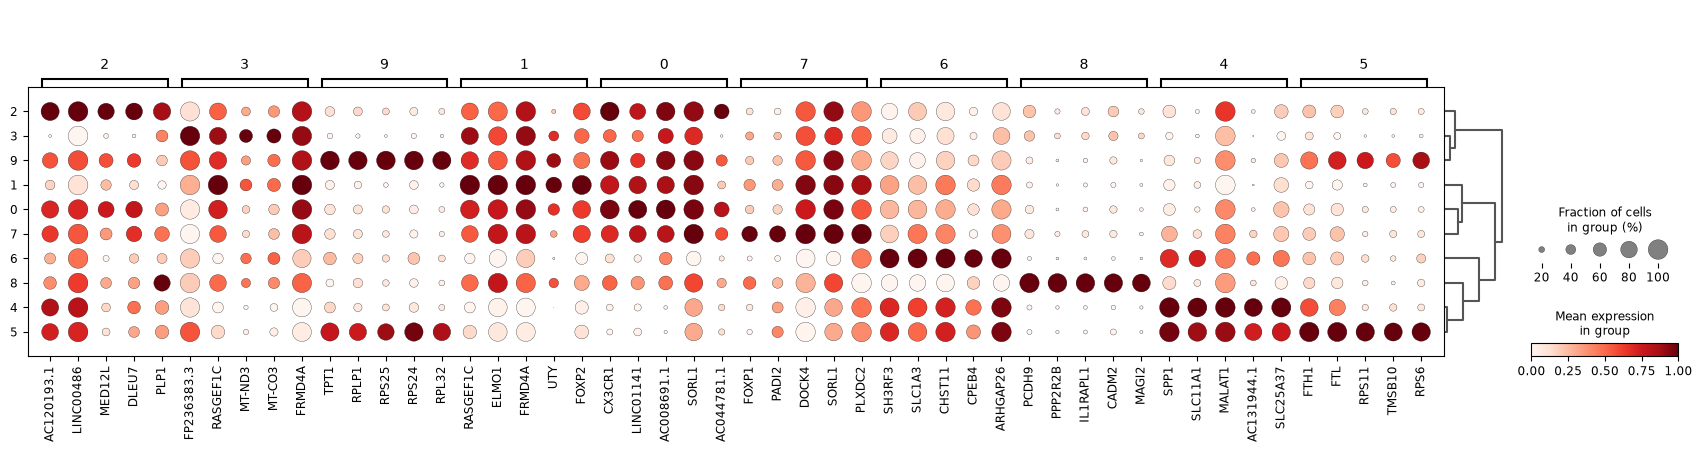

In [13]:
sc.tl.rank_genes_groups(smdata, 
                        use_raw=False, 
                        layer='CP10k_counts', 
                        groupby="leiden0.9", 
                        method="wilcoxon",
                        key_added='markers_0.9')
sc.pl.rank_genes_groups_dotplot(smdata, 
                                use_raw=False, 
                                layer='CP10k_counts', 
                                groupby="leiden0.9", 
                                standard_scale="var", 
                                n_genes=5,
                                key='markers_0.9',
                                save='_sr_0.9.png')

In [14]:
#Convert DE gene list into a dataframe, filter by FC and p-val and save as a csv 
sr_markers = sc.get.rank_genes_groups_df(smdata, None, key='markers_0.9')
sr_markers = sr_markers[(sr_markers['logfoldchanges'] > abs(0.5)) & (sr_markers['pvals_adj'] < 0.05)]
sr_markers.to_csv(script_loc.parent /'outputs/tables/sr_markers.csv', index=False)

In [15]:
sr_markers

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CX3CR1,23.153711,1.456487,1.333836e-118,3.212812e-114
1,0,LINC01141,22.774500,1.329051,8.207046e-115,9.884156e-111
2,0,AC008691.1,21.412884,1.570131,1.013441e-101,8.136921e-98
3,0,SORL1,21.227453,0.937746,5.327138e-100,3.207869e-96
4,0,AC044781.1,20.590702,1.471332,3.325115e-94,1.601841e-90
...,...,...,...,...,...,...
216899,9,SFMBT2,3.852160,0.697589,1.170806e-04,2.311575e-02
216900,9,PNRC1,3.756971,1.434386,1.719826e-04,3.314036e-02
216901,9,METTL9,3.660966,1.146917,2.512662e-04,4.765550e-02
216902,9,GPR34,3.646076,0.980673,2.662756e-04,4.958525e-02


In [16]:
#Grab the top 10 genes for each group by score and save to new csv file
top_10_genes = (
    sr_markers.groupby('group')
    .apply(lambda x: x.nlargest(10, 'scores'))
)
top_10_genes.to_csv(script_loc.parent /'outputs/tables/sr_top10_markers.csv')

In [17]:
#Create a dictionary of key identified microglia subtype and key marker genes
subtype_markers = {
    "Homeostatic": [
        "P2RY12", 'P2RY13', "TMEM119", "CX3CR1", 'HEXB', 'CSF1R'
    ],
    "Disease_Associated": [
        "APOE", "TREM2", "CST7", "LPL", "ITGAX", "CLEC7A", 'HLA-A', 'HLA-B', "CTSD", "CD74"
    ],
    "Interferon_Responsive": [
        "IFITM3", "OASL", "IRF7", "IFIT2", "IFIT3"
    ],
    "Senescent": [
        "CDKN2A", "CDKN1A", "CASP8", "CXCL8", "GLB1",
    ]
}

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\442246961.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(smdata,


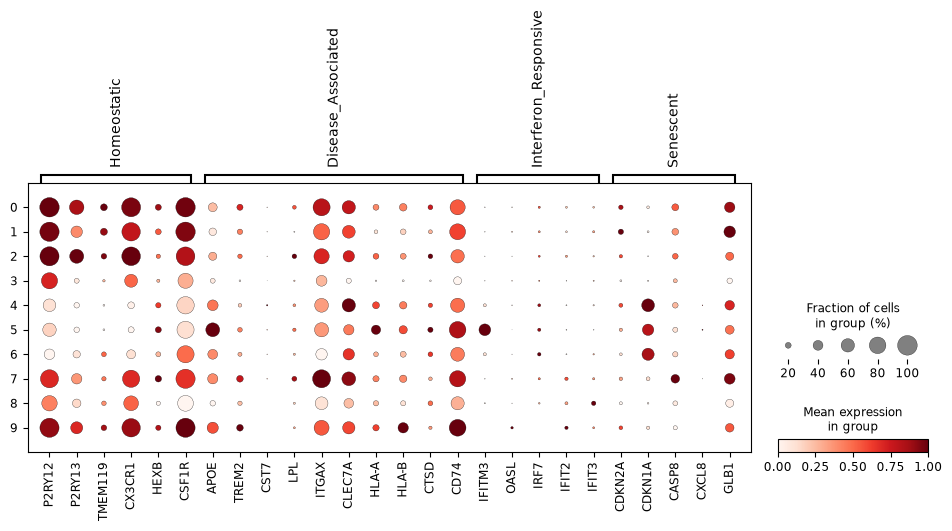

In [18]:
#Plot leiden 0.9 and 0.3 against these markers
sc.pl.dotplot(smdata, 
              subtype_markers, 
              use_raw=False, 
              layer='CP10k_counts', 
              groupby="leiden0.9", 
              standard_scale="var",
              save='_sr_0.9_cmarkers.png')

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\2756979780.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(smdata,


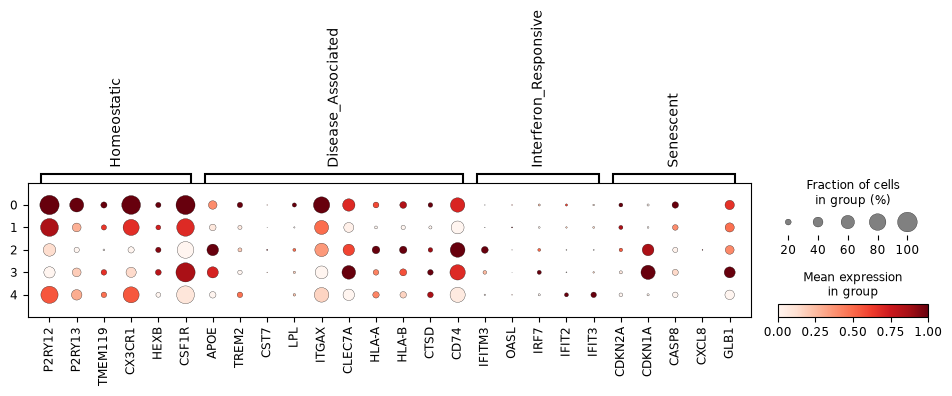

In [19]:
sc.pl.dotplot(smdata, 
              subtype_markers, 
              use_raw=False, 
              layer='CP10k_counts', 
              groupby="leiden0.3", 
              standard_scale="var",
              save='_0.3_cmarkers.png')

In [20]:
smdata

AnnData object with n_obs × n_vars = 6450 × 24087
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden0.3', 'leiden0.9'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_inte

In [21]:
sc.tl.filter_rank_genes_groups(
    smdata,
    groupby='leiden0.9',
    min_in_group_fraction=0.2,
    max_out_group_fraction=0.2,
    key='markers_0.9',
    key_added="markers_0.9_filtered",
)

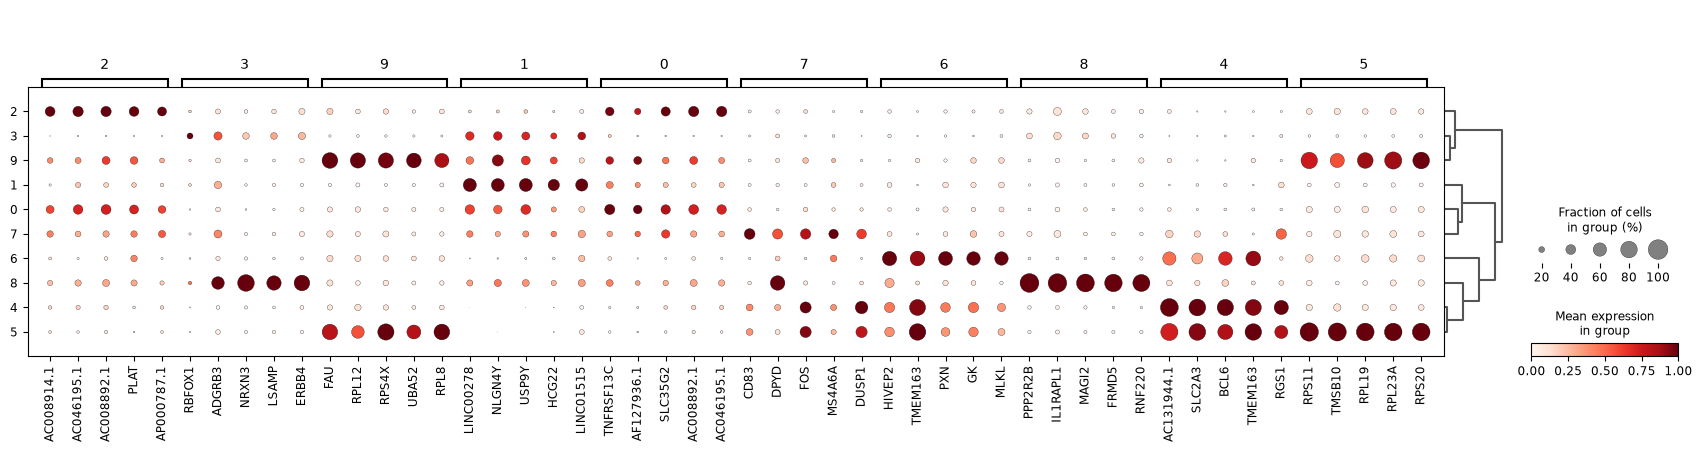

In [22]:
sc.pl.rank_genes_groups_dotplot(
    smdata,
    use_raw=False,
    layer='CP10k_counts',
    groupby="leiden0.9",
    standard_scale="var",
    n_genes=5,
    key="markers_0.9_filtered",
)

In [23]:
sc.tl.filter_rank_genes_groups(
    smdata,
    groupby='leiden0.3',
    min_in_group_fraction=0.2,
    max_out_group_fraction=0.2,
    key='markers_0.3',
    key_added="markers_0.3_filtered",
)

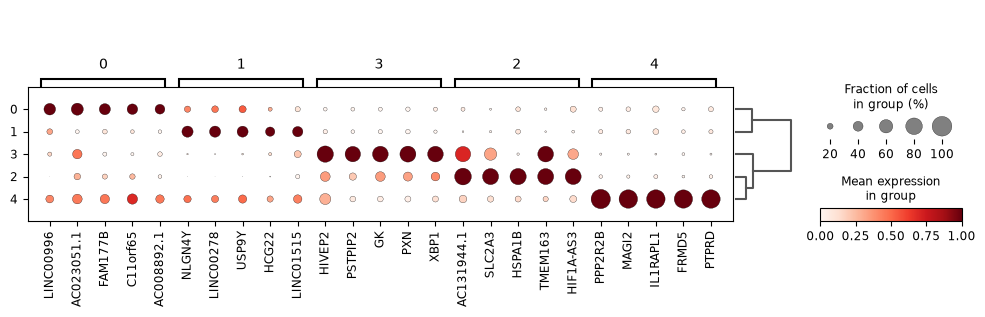

In [24]:
sc.pl.rank_genes_groups_dotplot(
    smdata,
    use_raw=False,
    layer='CP10k_counts',
    groupby="leiden0.3",
    standard_scale="var",
    n_genes=5,
    key="markers_0.3_filtered",
)

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\780097279.py:8: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.rank_genes_groups_dotplot(hmdata,


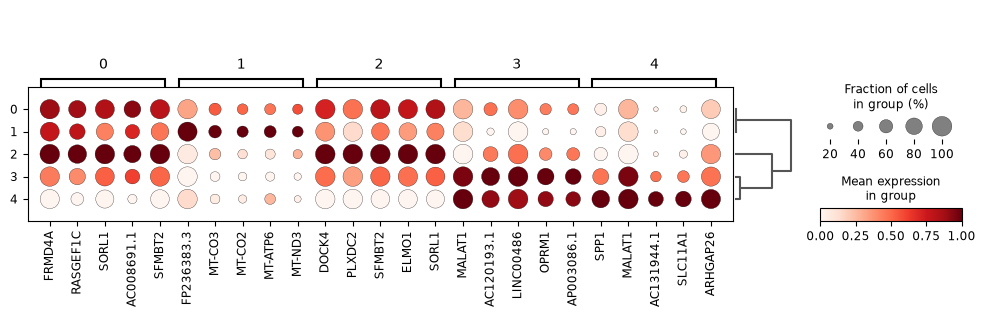

In [25]:
#Find cluster-specific differentially expressed genes and plot for leiden 0.3 and then 0.5
sc.tl.rank_genes_groups(hmdata, 
                        use_raw=False, 
                        layer='CP10k_counts', 
                        groupby="leiden0.3", 
                        method="wilcoxon",
                        key_added='markers_0.3')
sc.pl.rank_genes_groups_dotplot(hmdata, 
                                use_raw=False, 
                                layer='CP10k_counts', 
                                groupby="leiden0.3", 
                                standard_scale="var", 
                                n_genes=5,
                                key='markers_0.3',
                                save='_hm_0.3.png')

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\2044566176.py:7: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.rank_genes_groups_dotplot(hmdata,


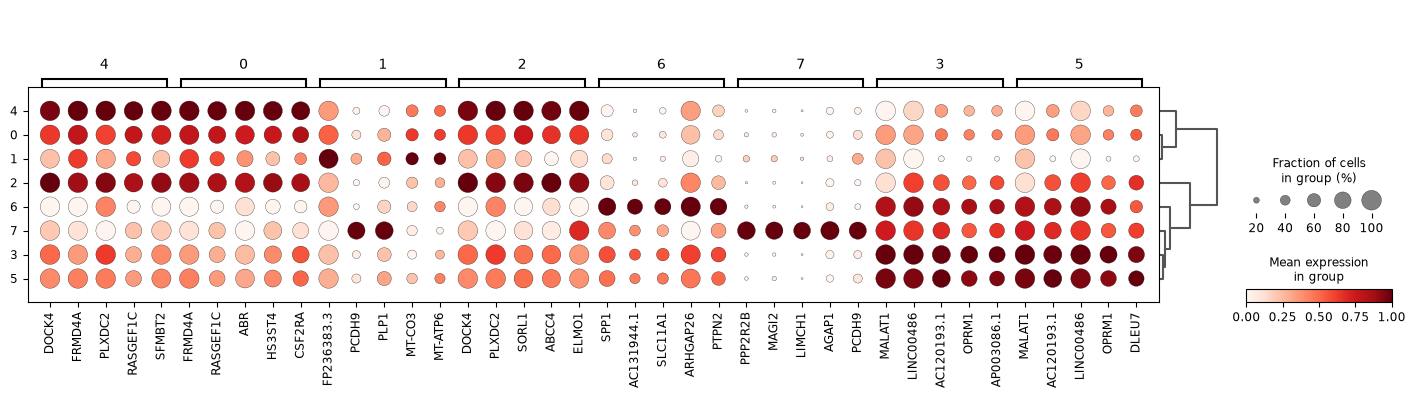

In [26]:
sc.tl.rank_genes_groups(hmdata, 
                        use_raw=False, 
                        layer='CP10k_counts', 
                        groupby="leiden0.5", 
                        method="wilcoxon",
                        key_added='markers_0.5')
sc.pl.rank_genes_groups_dotplot(hmdata, 
                                use_raw=False, 
                                layer='CP10k_counts', 
                                groupby="leiden0.5", 
                                standard_scale="var", 
                                n_genes=5,
                                key='markers_0.5',
                                save='hm_0.5.png')

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\2651505244.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(hmdata,


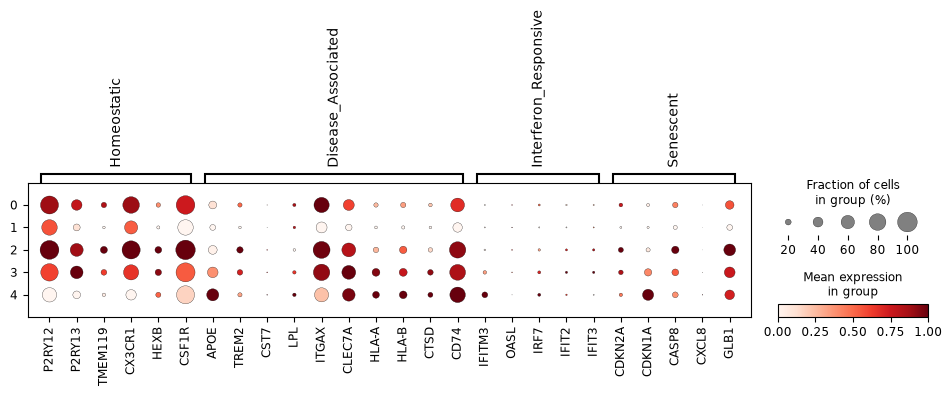

In [27]:
sc.pl.dotplot(hmdata, 
              subtype_markers, 
              use_raw=False, 
              layer='CP10k_counts', 
              groupby="leiden0.3", 
              standard_scale="var",
              save='0.3_cmarkers_hm.png')

C:\Users\chris\AppData\Local\Temp\ipykernel_4368\3346773608.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(hmdata,


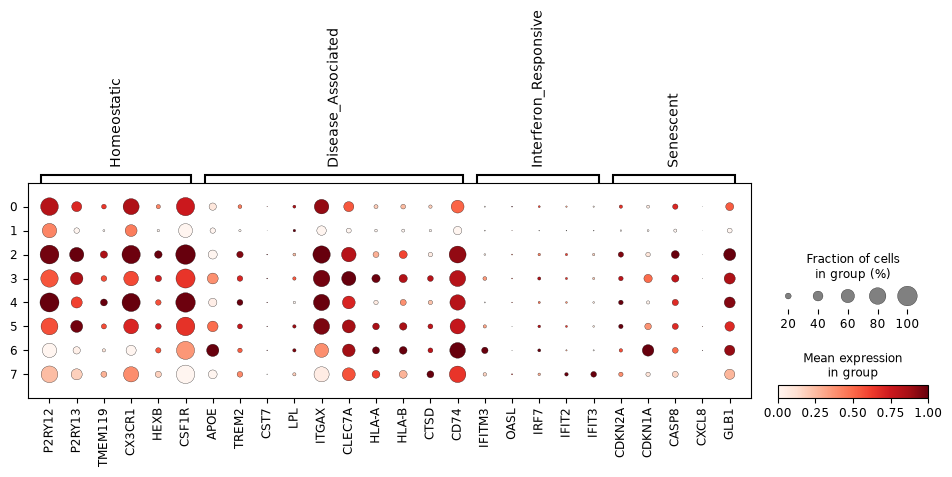

In [28]:
sc.pl.dotplot(hmdata, 
              subtype_markers, 
              use_raw=False, 
              layer='CP10k_counts', 
              groupby="leiden0.5", 
              standard_scale="var",
              save='0.5_cmarkers_hm.png')

In [ ]:
#Delete smdata filtered markers because it raised key error when writing it
#Probably due to lots of overlap and resulting non string values (?)
del smdata.uns['markers_0.9_filtered']
del smdata.uns['markers_0.3_filtered']

In [37]:
smdata

AnnData object with n_obs × n_vars = 6450 × 24087
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden0.3', 'leiden0.9'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_inte

In [38]:
hmdata.write_h5ad(data_loc / 'hm_mid_cluster.h5ad')
smdata.write_h5ad(data_loc / 'sr_mid_cluster.h5ad')